In [1]:
# Standard Libraries & Visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path

# Dynamic project paths
PROJECT_ROOT = Path(os.getcwd()).resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'online+retail' / 'Online Retail.xlsx'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'

sns.set_theme(style='whitegrid')
plt.rcParams['figure.autolayout'] = True
print(f"Project Root resolved to: {PROJECT_ROOT}")


Project Root resolved to: C:\--------projects------\Customer_Segmentation--UCI-


In [2]:
# Load dataset using dynamic path
if not RAW_DATA_PATH.exists():
    raise FileNotFoundError(f"Raw data file not found at: {RAW_DATA_PATH}")

print("Loading raw Excel dataset...")
cust = pd.read_excel(RAW_DATA_PATH)
print(f"Dataset loaded: {cust.shape[0]:,} rows, {cust.shape[1]} columns")


Loading raw Excel dataset...
Dataset loaded: 541,909 rows, 8 columns


In [3]:
print(f' columns in the dataset: {cust.columns}')
print(f' duplicated rows : {cust.duplicated().sum()}')
print(f' null values in the dataset: {cust.isnull().sum()/len(cust)*100.0}')

 columns in the dataset: Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')
 duplicated rows : 5268
 null values in the dataset: InvoiceNo       0.000000
StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64


In [4]:
df=cust.copy()

df_clean=df.dropna(subset=['CustomerID']).copy()
print(f'\n after dropping null values in customerid : {df_clean.shape[0]}')

df_clean=df_clean[(df_clean['Quantity']>0) & (df_clean['UnitPrice']>0)].copy()

print(f'after removing negative values : {df_clean.shape[0]} rows')

df_clean['total_price']=df_clean['Quantity']*df_clean['UnitPrice']




 after dropping null values in customerid : 406829
after removing negative values : 397884 rows


In [5]:
df_clean['CustomerID'].nunique()

4338

In [6]:
df_clean['CustomerID'].duplicated().sum()

np.int64(393546)

In [7]:
len(df_clean['CustomerID'])

397884

In [8]:
# cap outliers at 99 th percentile

qty_99=df_clean['Quantity'].quantile(0.99)
price_99=df_clean['UnitPrice'].quantile(0.99)
df_clean=df_clean[(df_clean['Quantity']<=qty_99) & (df_clean['UnitPrice']<=price_99)].copy()
print(f' after outlier capping to the (99th percentile): {df_clean.shape[0]} rows')
print(f" unique customers in the cleaning : {df_clean['CustomerID'].nunique()}")

 after outlier capping to the (99th percentile): 390260 rows
 unique customers in the cleaning : 4290


In [9]:
# time  features
df_clean['InvoiceDate']=pd.to_datetime(df_clean['InvoiceDate'])
df_clean['YearMonth']=df_clean['InvoiceDate'].dt.to_period('M')
df_clean['Hour']=df_clean['InvoiceDate'].dt.hour
df_clean['DayOfWeek']=df_clean['InvoiceDate'].dt.day_name()
df_clean['DayOfMonth']=df_clean['InvoiceDate'].dt.day



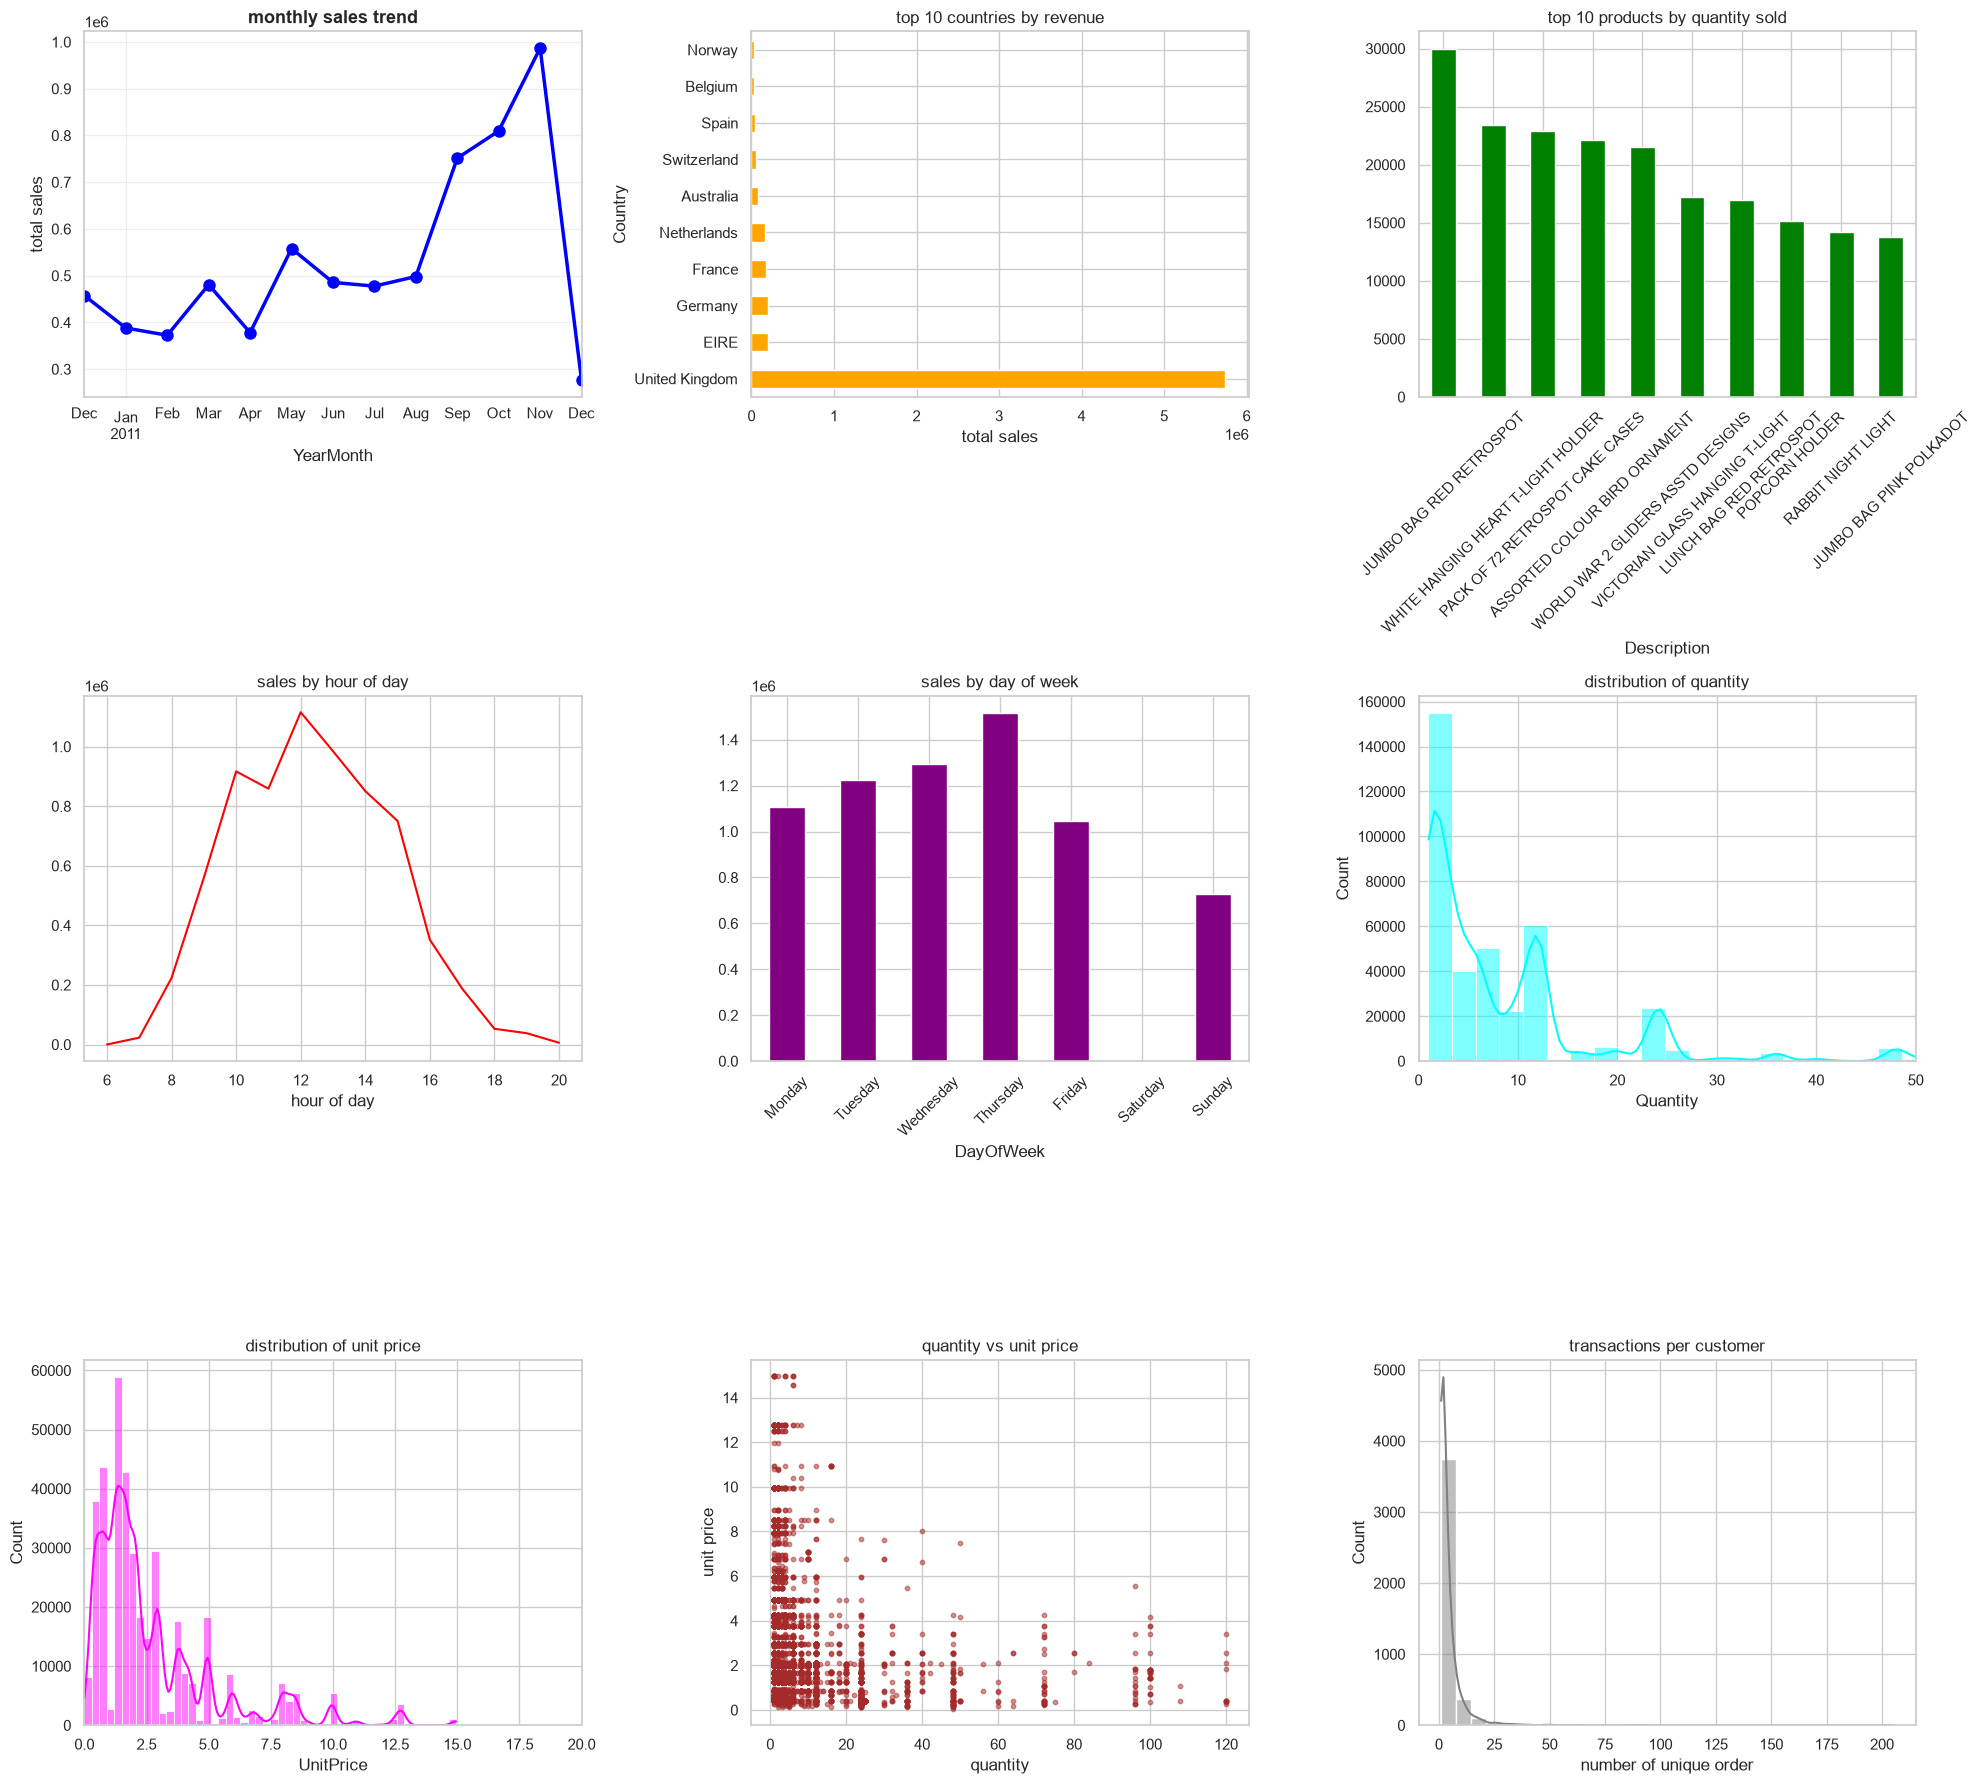

In [10]:
fig,axes=plt.subplots(3,3,figsize=(20,18))

monthly_sales=df_clean.groupby('YearMonth')['total_price'].sum()
monthly_sales.plot(kind='line',ax=axes[0,0],marker='o',color='blue',linewidth=2.5,markersize=8)
axes[0,0].set_title('monthly sales trend', fontsize=13,fontweight='bold')
axes[0,0].set_ylabel('total sales')
axes[0,0].grid(True,alpha=0.3)

country_sales=df_clean.groupby('Country')['total_price'].sum().sort_values(ascending=False).head(10)
country_sales.plot(kind='barh',ax=axes[0,1],color='orange')
axes[0,1].set_title('top 10 countries by revenue')
axes[0,1].set_xlabel('total sales')

top_products=df_clean.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)
top_products.plot(kind='bar',ax=axes[0,2],color='green')
axes[0,2].set_title('top 10 products by quantity sold')
axes[0,2].tick_params(axis='x',rotation=45)

hourly_sales=df_clean.groupby('Hour')['total_price'].sum()
hourly_sales.plot(kind='line',ax=axes[1,0],color='red')
axes[1,0].set_title('sales by hour of day')
axes[1,0].set_xlabel('hour of day')

day_order=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
daily_sales=df_clean.groupby('DayOfWeek')['total_price'].sum().reindex(day_order)
daily_sales.plot(kind='bar',ax=axes[1,1],color='purple')
axes[1,1].set_title('sales by day of week')
axes[1,1].tick_params(axis='x',rotation=45)

sns.histplot(df_clean['Quantity'],bins=50,kde=True,ax=axes[1,2],color='cyan')
axes[1,2].set_title('distribution of quantity')
axes[1,2].set_xlim(0,50)

sns.histplot(df_clean["UnitPrice"],bins=50,kde=True,ax=axes[2,0],color='magenta')
axes[2,0].set_title('distribution of unit price')
axes[2,0].set_xlim(0,20)

sample=df_clean.sample(min(5000,len(df_clean)))
axes[2,1].scatter(sample['Quantity'],sample['UnitPrice'],alpha=0.5,s=10,color='brown')
axes[2,1].set_title('quantity vs unit price')
axes[2,1].set_xlabel('quantity')
axes[2,1].set_ylabel('unit price')

txn_per_cust=df_clean.groupby('CustomerID')['InvoiceNo'].nunique()
sns.histplot(txn_per_cust,bins=30,kde=True,ax=axes[2,2],color='gray')
axes[2,2].set_title('transactions per customer')
axes[2,2].set_xlabel('number of unique order')

plt.tight_layout()
plt.show()

In [11]:
# rfm
from datetime import timedelta


reference_date=df_clean['InvoiceDate'].max()+ timedelta(days=1)
print(f' reference date: {reference_date}')

rfm=df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date -x.max()).days,
    'InvoiceNo': 'nunique',
    'total_price': 'sum'
}).reset_index()
rfm.columns=['CustomerID','Recency','Frequency','Monetary']

advanced=df_clean.groupby('CustomerID').agg({
    'total_price': ['mean','max','min','std','count'],
    'Quantity': 'sum',
    'StockCode': 'nunique',
    'InvoiceDate': ['min','max']
}).reset_index()

advanced.columns=['CustomerID', 'AvgOrderValue', 'MaxOrderValue', 'MinOrderValue', 'OrderStdDev', 
                    'NumTransactions', 'TotalQuantity', 'ProductVariety', 'FirstPurchase', 'LastPurchase']

advanced['OrderStdDev']=advanced['OrderStdDev'].fillna(0)
advanced['LifespanDays']=(advanced['LastPurchase']-advanced['FirstPurchase']).dt.days

rfm=rfm.merge(advanced,on='CustomerID')
print(f' rfm dataset : {rfm.shape}')
print(rfm[['Recency','Frequency','Monetary','AvgOrderValue','ProductVariety','LifespanDays']].head(10))



 reference date: 2011-12-10 12:50:00
 rfm dataset : (4290, 14)
   Recency  Frequency  Monetary  AvgOrderValue  ProductVariety  LifespanDays
0        2          7   4060.40      22.433149             102           365
1       75          4   1186.68      56.508571              15           282
2       19          1   1353.80      19.340000              70             0
3      310          1    294.40      18.400000              16             0
4       36          7   1385.74      17.996623              57           260
5      204          1     89.00      22.250000               4             0
6      232          1   1028.55      18.700909              55             0
7      214          1    459.40      35.338462              13             0
8       23          3   2487.43      42.886724              52           302
9       33          1   6182.67      47.559000             130             0


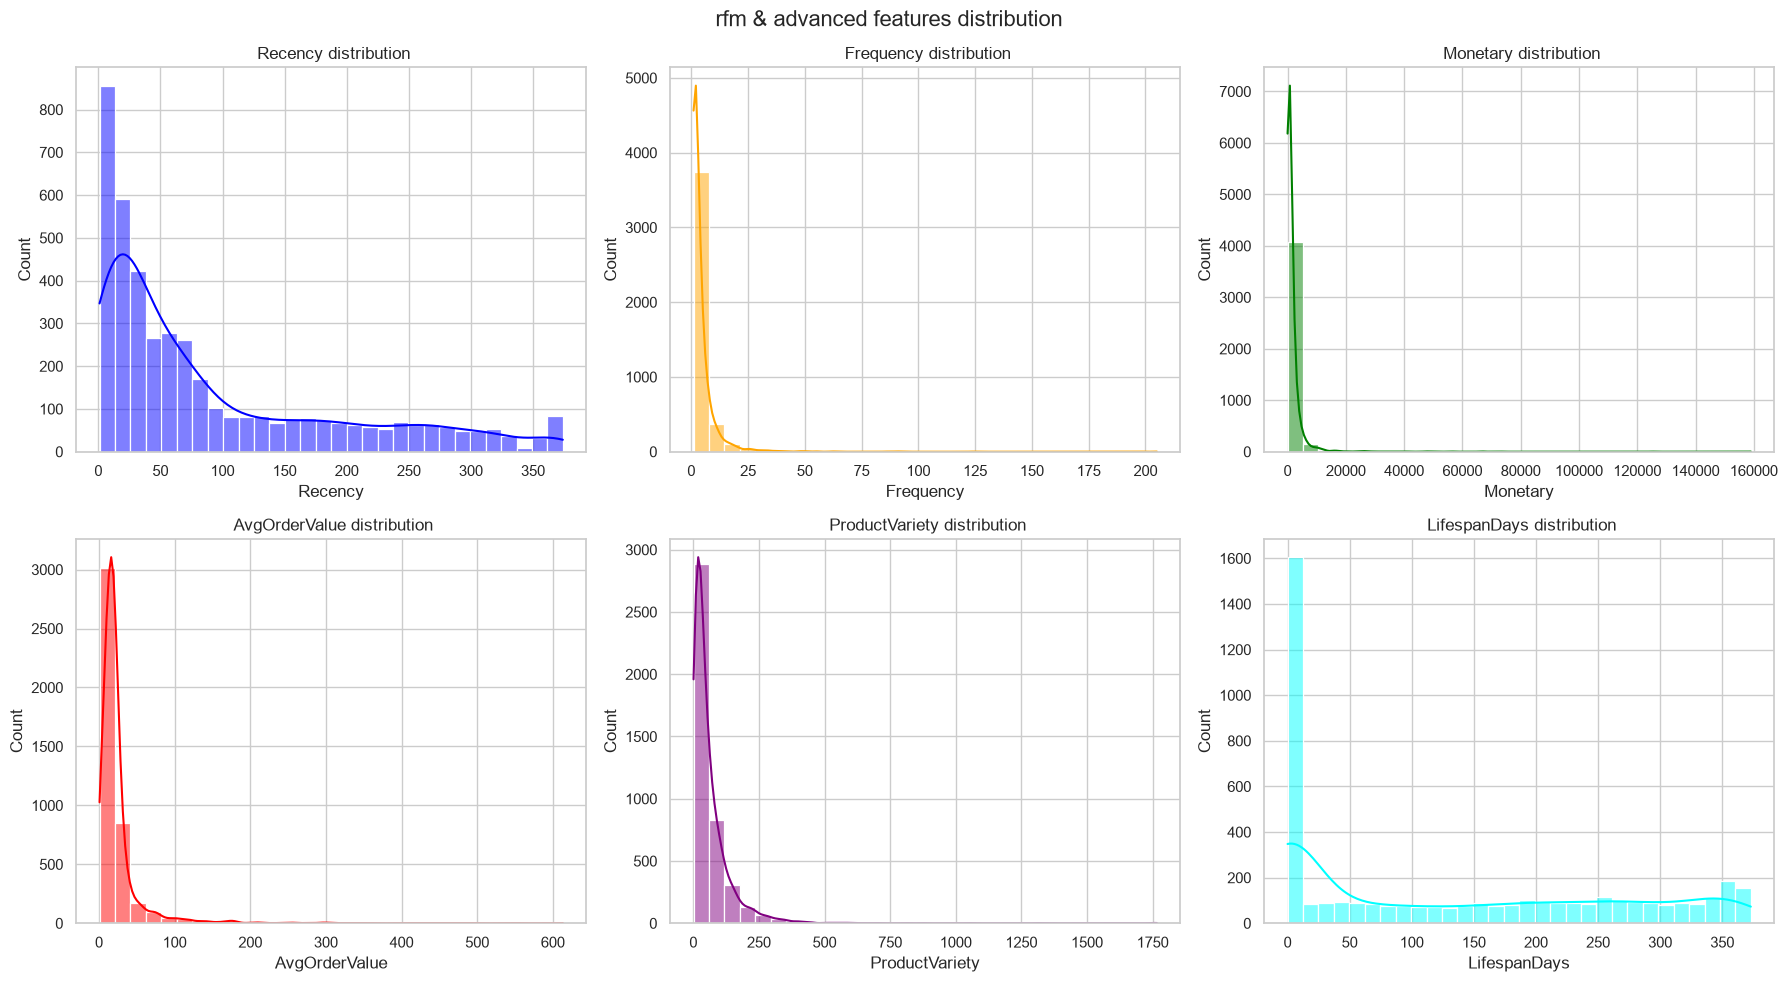

In [12]:
#rfm distribution
fig,axes=plt.subplots(2,3,figsize=(18,10))
features_plot=['Recency','Frequency','Monetary','AvgOrderValue','ProductVariety','LifespanDays']
colors=['blue','orange','green','red','purple','cyan']

for ax,feat,col in zip (axes.flat,features_plot,colors):
    sns.histplot(rfm[feat],bins=30,kde=True,ax=ax,color=col)
    ax.set_title(f' {feat} distribution')
plt.suptitle('rfm & advanced features distribution ', fontsize=16)
plt.tight_layout()
plt.show()


In [13]:
from sklearn.preprocessing import StandardScaler

In [14]:
# select features
features=['Recency','Frequency','Monetary','AvgOrderValue','ProductVariety','LifespanDays']
x=rfm[features].copy()
x_log=np.log1p(x)

for col in features:
    upper=x_log[col].quantile(0.99)
    lower=x_log[col].quantile(0.01)
    x_log[col]=np.clip(x_log[col],lower,upper)

scaler=StandardScaler()
x_scaled=scaler.fit_transform(x_log)

print(f' {pd.DataFrame(x_scaled,columns=features).describe().round(2)}')


        Recency  Frequency  Monetary  AvgOrderValue  ProductVariety  \
count  4290.00    4290.00   4290.00        4290.00         4290.00   
mean      0.00       0.00      0.00          -0.00           -0.00   
std       1.00       1.00      1.00           1.00            1.00   
min      -2.34      -0.97     -2.29          -2.11           -2.58   
25%      -0.66      -0.97     -0.70          -0.49           -0.65   
50%       0.09      -0.36     -0.04           0.01            0.03   
75%       0.85       0.70      0.70           0.40            0.73   
max       1.55       3.14      2.49           3.18            2.07   

       LifespanDays  
count       4290.00  
mean           0.00  
std            1.00  
min           -1.28  
25%           -1.28  
50%            0.51  
75%            0.91  
max            1.06  


In [15]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.cluster import (
    KMeans, MiniBatchKMeans, AgglomerativeClustering, DBSCAN, 
    OPTICS, Birch, SpectralClustering, MeanShift, AffinityPropagation
)
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import cdist
import warnings
warnings.filterwarnings('ignore')

In [16]:
# unsupervised learning applying algorithms
results={}
cluster_labels={}

print(f'\n k-means clustering')
kmeans=KMeans(n_clusters=4,random_state=42,n_init=10,init='k-means++')
labels_km=kmeans.fit_predict(x_scaled)
cluster_labels['k-means']=labels_km

print(f' minibatch k-means')
mb_kmeans=MiniBatchKMeans(n_clusters=4,random_state=42,n_init=10,batch_size=100)
labels_mb=mb_kmeans.fit_predict(x_scaled)
cluster_labels['MiniBatch k-Means']=labels_mb

print(f' hierarchical clustering')
hier=AgglomerativeClustering(n_clusters=4,linkage='ward')
labels_hw=hier.fit_predict(x_scaled)
cluster_labels['hierarchical']=labels_hw

print(f' hierarchical clustering (complete)')
hier_comp=AgglomerativeClustering(n_clusters=4,linkage='complete')
labels_hc=hier_comp.fit_predict(x_scaled)
cluster_labels['hierarchical (complete)']=labels_hc

print(f'hiearchical clustering (average)')
hier_avg=AgglomerativeClustering(n_clusters=4,linkage='average')
labels_ha=hier_avg.fit_predict(x_scaled)
cluster_labels['Hierarchical (average)']=labels_ha

print(f' dbscan clustering')
from sklearn.neighbors import NearestNeighbors
neigh=NearestNeighbors(n_neighbors=5)
neigh.fit(x_scaled)
distances, _ =neigh.kneighbors(x_scaled)
distances=np.sort(distances[:,4])
eps_optimal=np.percentile(distances,90)
dbscan=DBSCAN(eps=eps_optimal,min_samples=10)
labels_db=dbscan.fit_predict(x_scaled)
cluster_labels['DBSCAN']=labels_db

print(f' optics clustering')
optics=OPTICS(min_samples=5,xi=0.03,min_cluster_size=0.03,cluster_method='xi')
labels_op=optics.fit_predict(x_scaled)
cluster_labels['OPTICS']=labels_op

print(f' gaussian mixture clustering')
gmm=GaussianMixture(n_components=4,random_state=42)
labels_gmm=gmm.fit_predict(x_scaled)
cluster_labels['gaussian mixture']=labels_gmm

print(f'mean shift clustering')
mean_shift=MeanShift(bandwidth=None,bin_seeding=True)
labels_ms=mean_shift.fit_predict(x_scaled)
cluster_labels['mean_shift']=labels_ms

print(f' spectral clustering')
spectral=SpectralClustering(n_clusters=4,random_state=42,affinity='nearest_neighbors')
labels_sc=spectral.fit_predict(x_scaled)
cluster_labels['spectral']=labels_sc

print(f' brich (balanced iterative reducing and clustering)')
birch=Birch(n_clusters=4,threshold=0.5)
labels_br=birch.fit_predict(x_scaled)
cluster_labels['birch']=labels_br

print(f' affinity propagation clustering')
ap=AffinityPropagation(random_state=42,damping=0.9)
labels_ap=ap.fit_predict(x_scaled)
cluster_labels['affinity propagation']=labels_ap


print()
print(f' clustering distribution')

for name,labels in cluster_labels.items():
    unique_clusters=len(set(labels))
    noise=list(labels).count(-1) if -1 in labels else 0
    print(f' {name:25s}: {unique_clusters} clusters | noise / outliers: {noise}')



 k-means clustering
 minibatch k-means
 hierarchical clustering
 hierarchical clustering (complete)
hiearchical clustering (average)
 dbscan clustering
 optics clustering
 gaussian mixture clustering
mean shift clustering
 spectral clustering
 brich (balanced iterative reducing and clustering)
 affinity propagation clustering

 clustering distribution
 k-means                  : 4 clusters | noise / outliers: 0
 MiniBatch k-Means        : 4 clusters | noise / outliers: 0
 hierarchical             : 4 clusters | noise / outliers: 0
 hierarchical (complete)  : 4 clusters | noise / outliers: 0
 Hierarchical (average)   : 4 clusters | noise / outliers: 0
 DBSCAN                   : 4 clusters | noise / outliers: 351
 OPTICS                   : 2 clusters | noise / outliers: 2862
 gaussian mixture         : 4 clusters | noise / outliers: 0
 mean_shift               : 1 clusters | noise / outliers: 0
 spectral                 : 4 clusters | noise / outliers: 0
 birch                    : 4 

In [17]:
# comprehensive evaluation of clustering algorithms

eval_metrics=[]

for name,labels in cluster_labels.items():
    unique_clusters=len(set(labels))

    if unique_clusters <2:
        eval_metrics.append({
            'algorithm': name,
            'clusters': unique_clusters,
            'silhouette': np.nan,
            'calinski_harabasz': np.nan,
            'davies_bouldin': np.nan,
            'noise_points': list(labels).count(-1)


        })

        continue

    mask=labels !=-1
    if mask.sum() > 10 and len(set(labels[mask]))>=2:
        sil=silhouette_score(x_scaled[mask],labels[mask])
        ch=calinski_harabasz_score(x_scaled[mask],labels[mask])
        db=davies_bouldin_score(x_scaled[mask],labels[mask])
    else:
        sil=silhouette_score(x_scaled,labels)
        ch=calinski_harabasz_score(x_scaled,labels)
        db=davies_bouldin_score(x_scaled,labels)


    eval_metrics.append({
        'algorithm': name,
        'clusters': unique_clusters,
        'silhouette': sil,
        'calinski_harabasz': ch,
        'davies_bouldin': db,
        'noise_points': list(labels).count(-1)
    })

eval_df=pd.DataFrame(eval_metrics)

print(f' \n clustering evaluation metrics')

print(eval_df.round(3).to_string(index=False))

valid_eval=eval_df[(eval_df['clusters']>=2) & (eval_df['clusters'] <=8)].copy()
best_idx=valid_eval['silhouette'].idxmax()
best_algo=valid_eval.loc[best_idx,'algorithm']

print(f'\n best clustering algorithm based on silhouette {best_algo}')
print(f' silhouette score: {valid_eval.loc[best_idx,"silhouette"]:.4f}')

 
 clustering evaluation metrics
              algorithm  clusters  silhouette  calinski_harabasz  davies_bouldin  noise_points
                k-means         4       0.284           2099.810           1.277             0
      MiniBatch k-Means         4       0.263           1949.044           1.287             0
           hierarchical         4       0.220           1795.218           1.483             0
hierarchical (complete)         4       0.089           1026.662           1.573             0
 Hierarchical (average)         4       0.288            921.245           0.879             0
                 DBSCAN         4       0.302           1569.064           0.890           351
                 OPTICS         2       0.333           2374.867           1.077          2862
       gaussian mixture         4       0.148           1460.689           2.149             0
             mean_shift         1         NaN                NaN             NaN             0
               sp

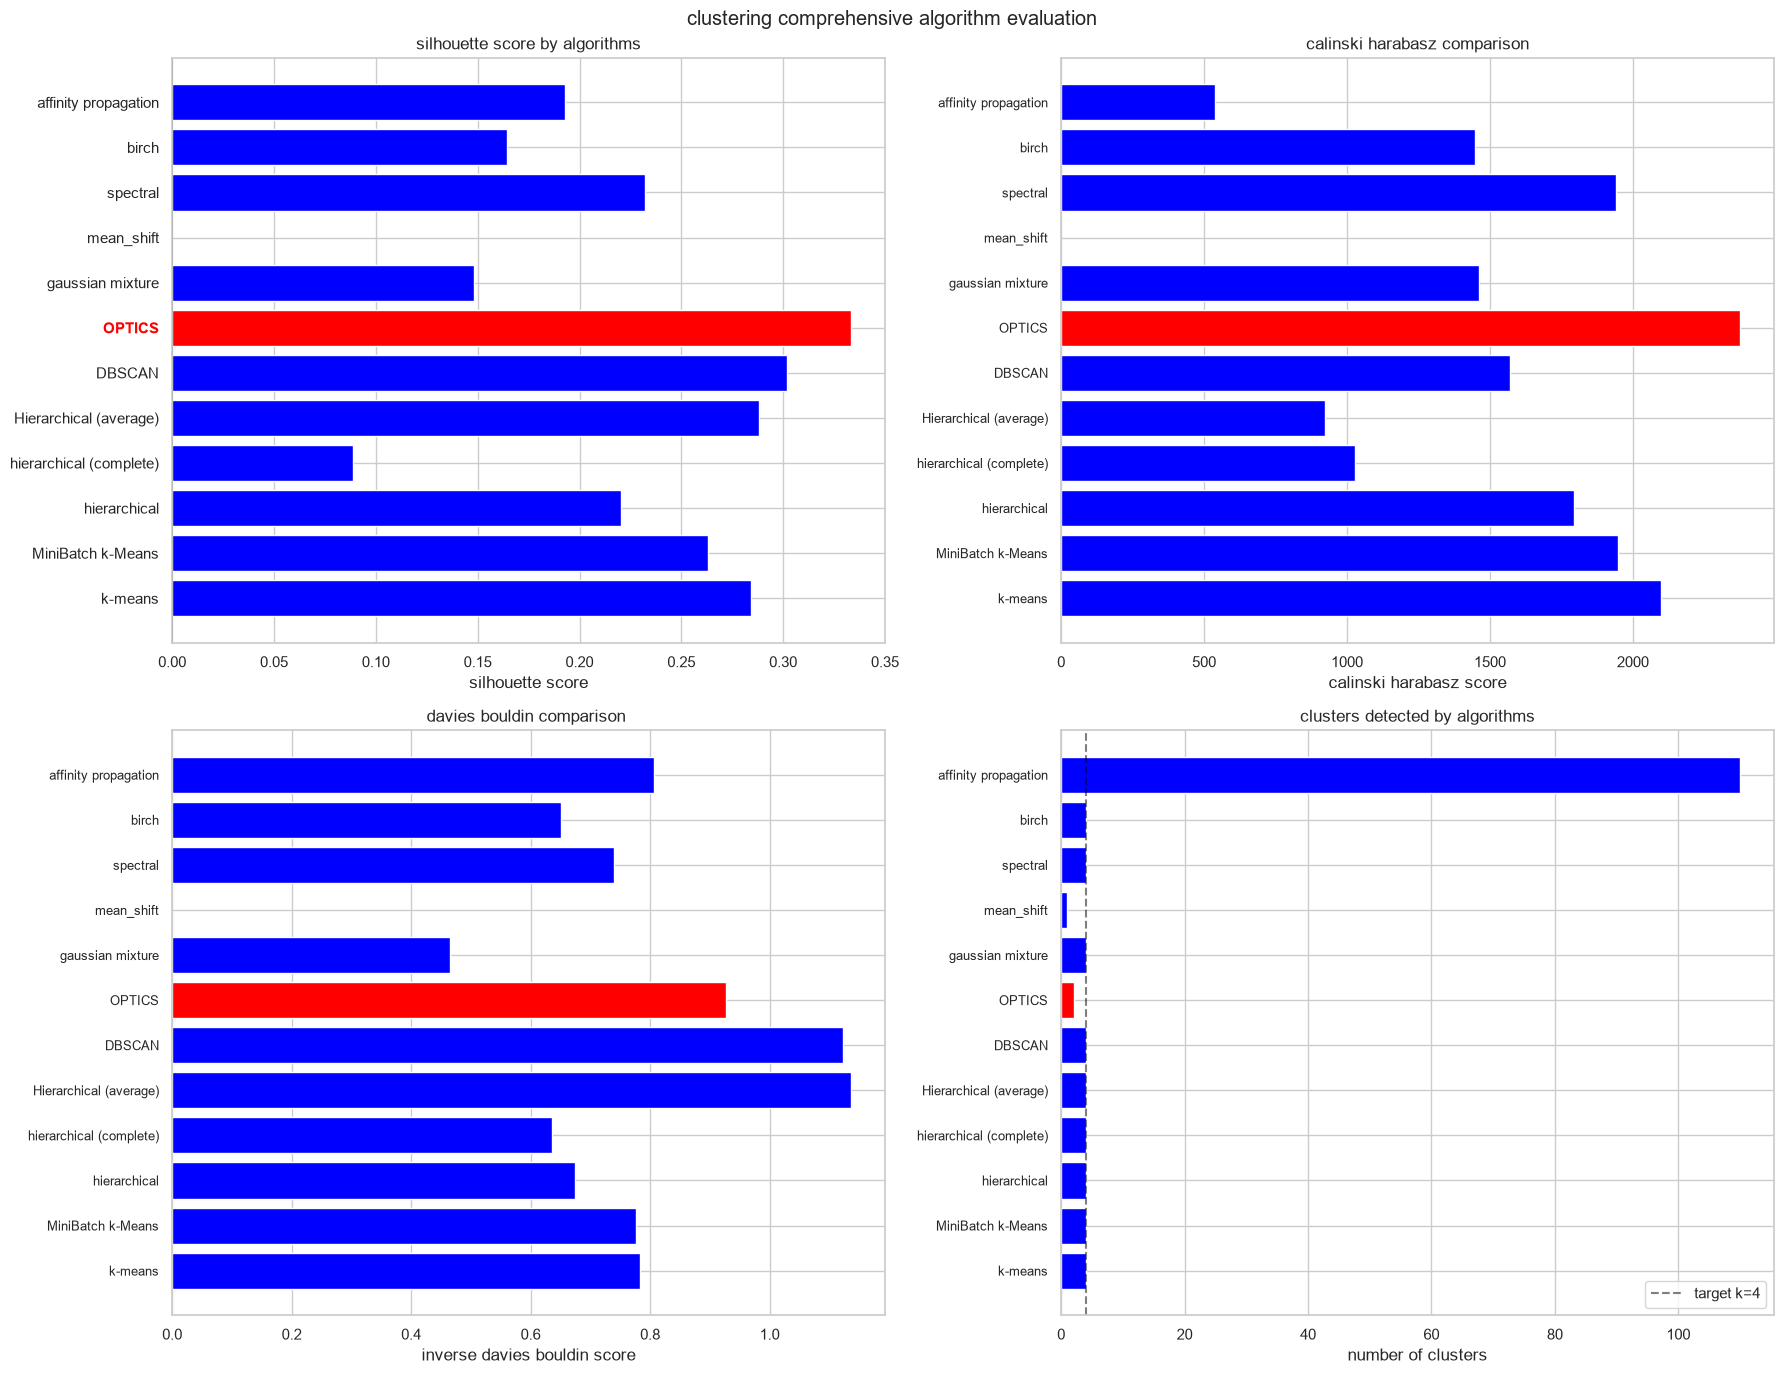

In [18]:
fig,axes=plt.subplots(2,2,figsize=(18,14))

#silhouette score plot

x_pos=np.arange(len(eval_df))
colors=['blue' if algo!= best_algo else "red" for algo in eval_df['algorithm']]
bars1=axes[0,0].barh(x_pos,eval_df['silhouette'],color=colors)
axes[0,0].set_yticks(x_pos)
axes[0,0].set_yticklabels(eval_df['algorithm'])
axes[0,0].set_xlabel('silhouette score')
axes[0,0].set_title('silhouette score by algorithms')
axes[0,0].axvline(x=0,color='black',linewidth=0.5)
best_bar_idx=eval_df[eval_df['algorithm']==best_algo].index[0]
axes[0,0].get_yticklabels()[best_bar_idx].set_fontweight('bold')
axes[0,0].get_yticklabels()[best_bar_idx].set_color('red')


bars2=axes[0,1].barh(x_pos,eval_df['calinski_harabasz'],color=colors)
axes[0,1].set_yticks(x_pos)
axes[0,1].set_yticklabels(eval_df['algorithm'],fontsize=9)
axes[0,1].set_xlabel('calinski harabasz score')
axes[0,1].set_title('calinski harabasz comparison')

db_inv=1/(eval_df['davies_bouldin']+0.001)
bars3=axes[1,0].barh(x_pos,db_inv,color=colors)
axes[1,0].set_yticks(x_pos)
axes[1,0].set_yticklabels(eval_df['algorithm'],fontsize=9)
axes[1,0].set_xlabel('inverse davies bouldin score')
axes[1,0].set_title('davies bouldin comparison ')

bars4=axes[1,1].barh(x_pos,eval_df['clusters'],color=colors)
axes[1,1].set_yticks(x_pos)
axes[1,1].set_yticklabels(eval_df['algorithm'],fontsize=9)
axes[1,1].set_xlabel('number of clusters')
axes[1,1].set_title('clusters detected by algorithms')
axes[1,1].axvline(x=4,color='black',linestyle='--',alpha=0.5,label='target k=4')
axes[1,1].legend()

plt.suptitle('clustering comprehensive algorithm evaluation')
plt.tight_layout()
plt.show()

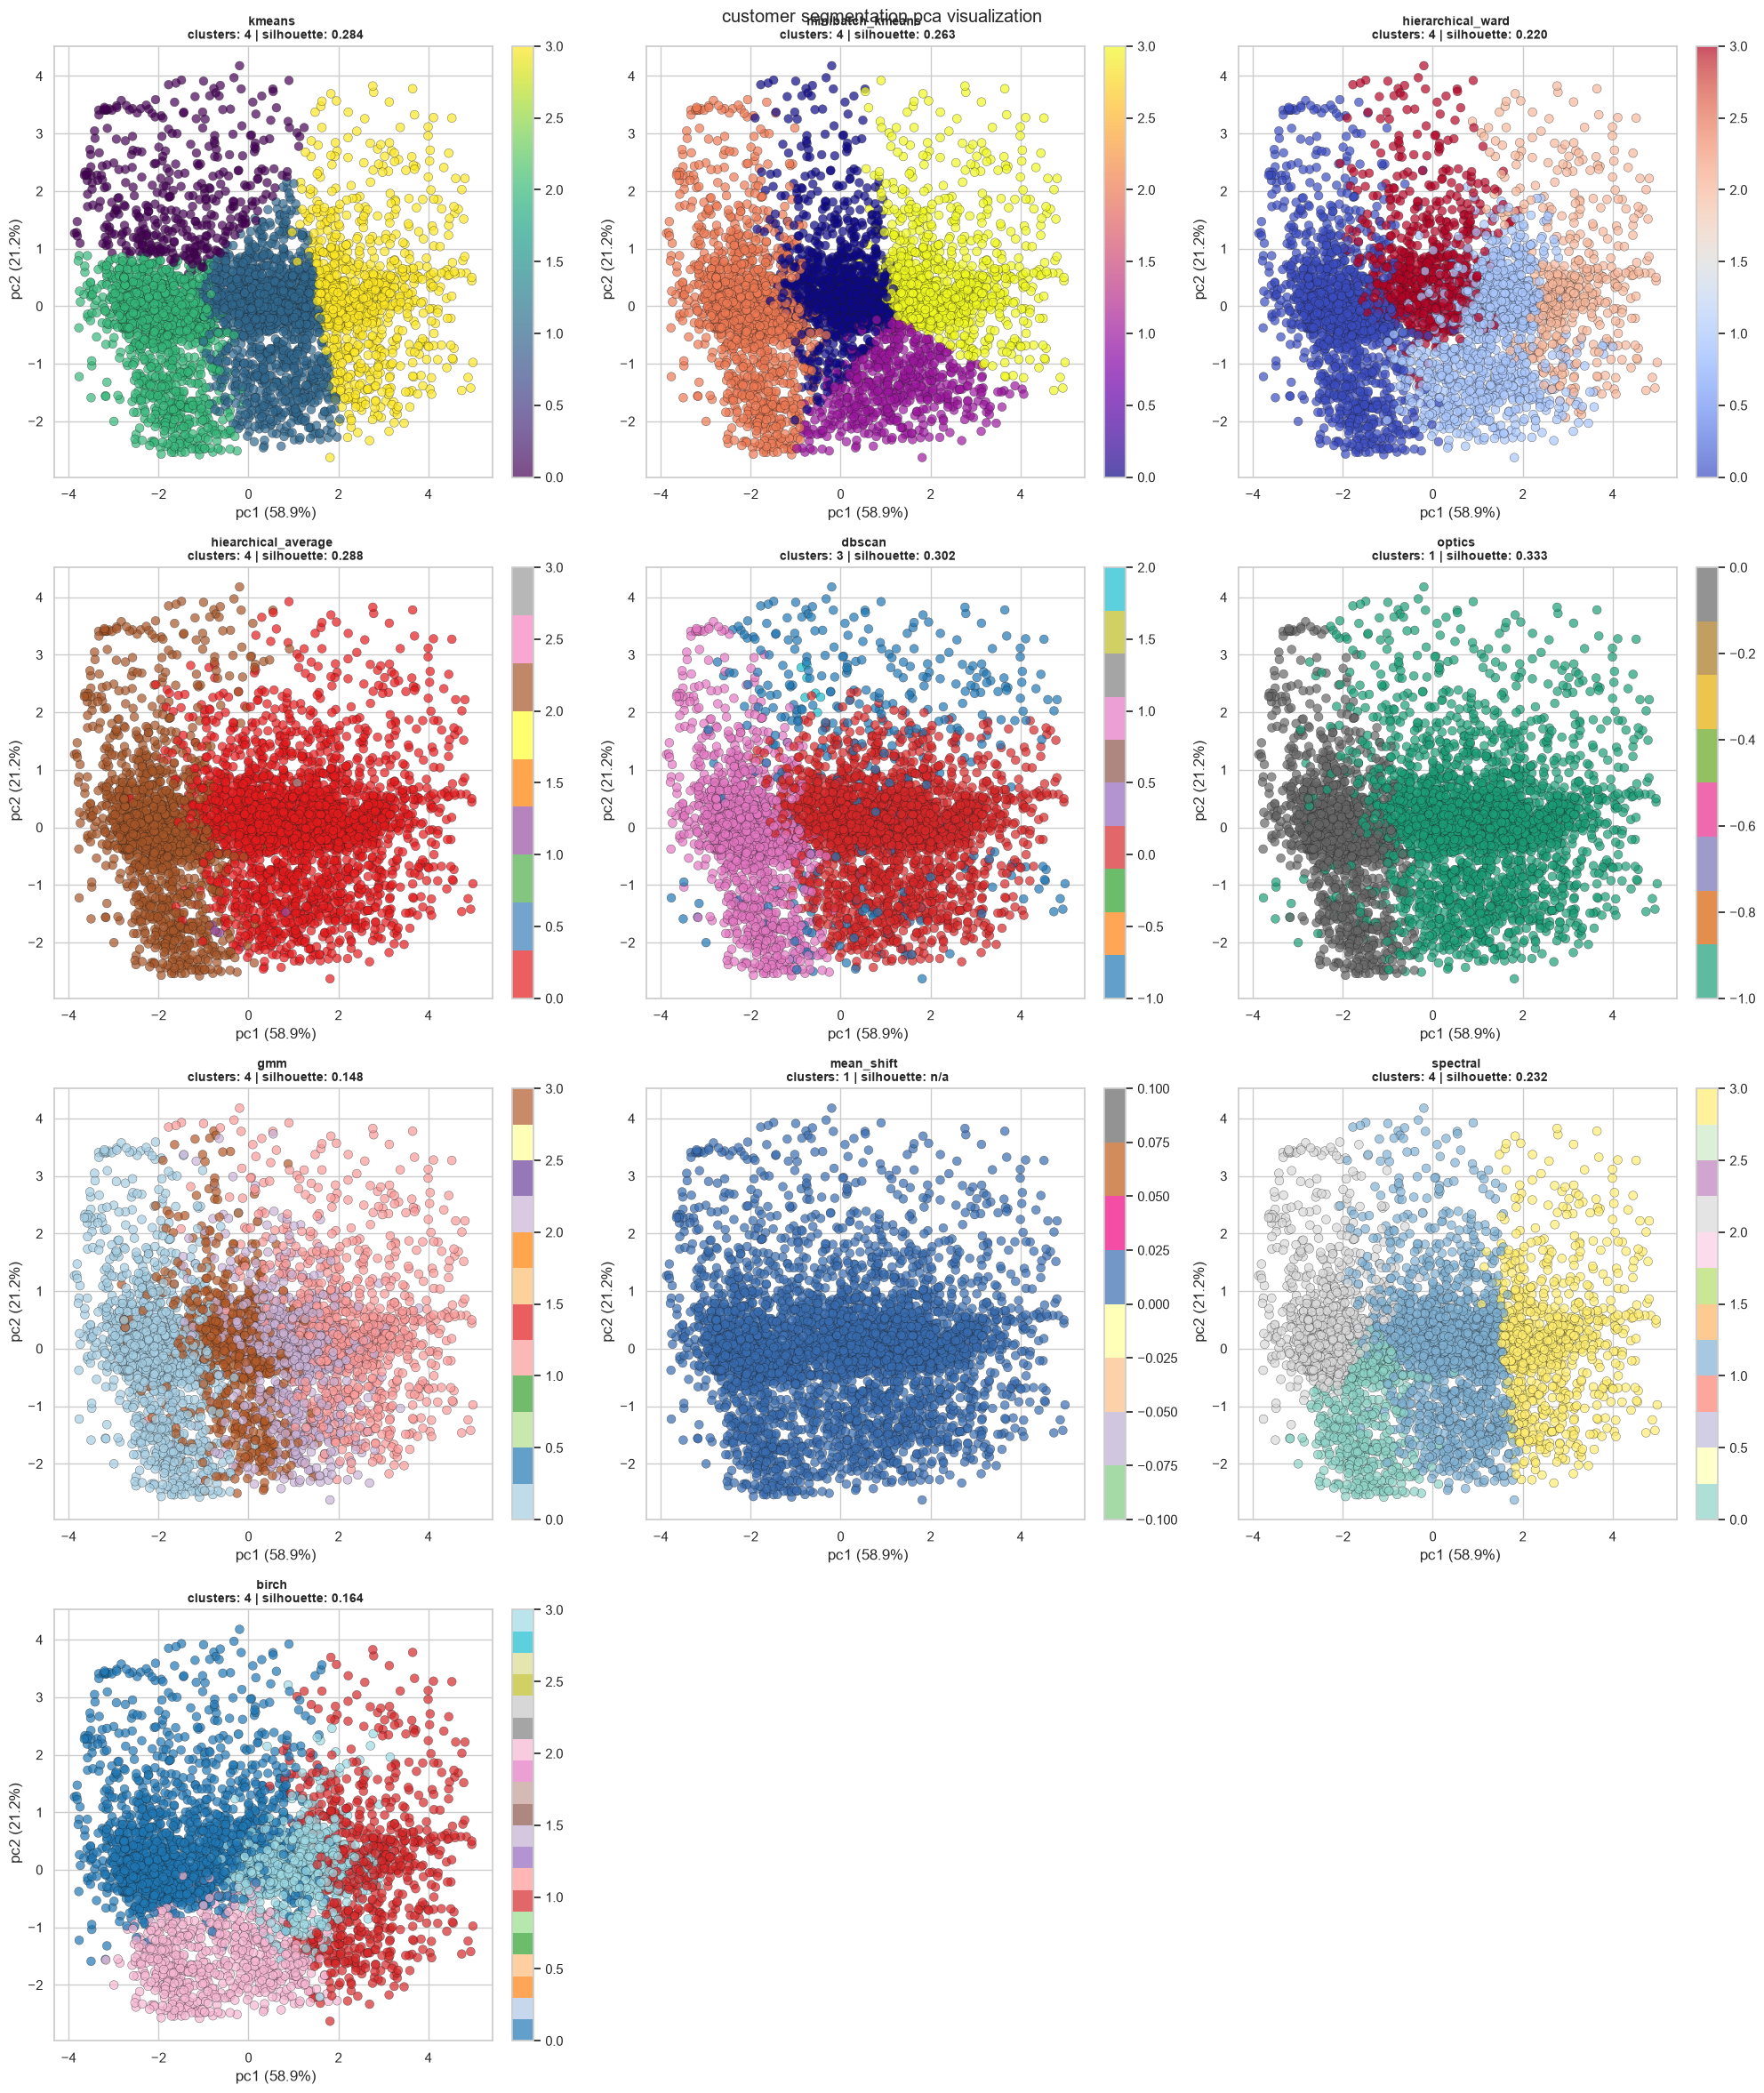

 pca total variance explained: 80.11%


In [19]:
# pca visualization of all algo
pca=PCA(n_components=2)
x_pca=pca.fit_transform(x_scaled)


vis_algo=dict(
    kmeans=cluster_labels['k-means'],
    minibatch_kmeans=cluster_labels['MiniBatch k-Means'],
    hierarchical_ward=cluster_labels['hierarchical'],
    hiearchical_average=cluster_labels['Hierarchical (average)'],
    dbscan=cluster_labels['DBSCAN'],
    optics=cluster_labels['OPTICS'],
    gmm=cluster_labels['gaussian mixture'],
    mean_shift=cluster_labels['mean_shift'],
    spectral=cluster_labels['spectral'],
    birch=cluster_labels['birch']

 )

n_cols=3
n_rows=int(np.ceil(len(vis_algo)/n_cols))
fig,axes=plt.subplots(n_rows,n_cols,figsize=(20,6*n_rows))
axes=np.array(axes).reshape(-1)

cmaps=['viridis','plasma','coolwarm','Set1','tab10','Dark2','Paired','Accent','Set3','tab20']

for idx,(name,labels) in enumerate(vis_algo.items()):
    ax=axes[idx]
    mask=labels!=-1
    n_clusters=len(set(labels[mask])) if mask.any() else 0

    scatter=ax.scatter(x_pca[:,0],x_pca[:,1],c=labels,cmap=cmaps[idx % len(cmaps)],alpha=0.7,s=50,edgecolors='k',linewidth=0.3)

    if mask.sum()>10 and len(set(labels[mask]))>=2:
        sil=silhouette_score(x_scaled[mask],labels[mask])
    elif len(set(labels))>=2:
        sil=silhouette_score(x_scaled,labels)
    else:
        sil=np.nan

    sil_text=f'{sil:.3f}' if np.isfinite(sil) else 'n/a'
    ax.set_title(f'{name} \n clusters: {n_clusters} | silhouette: {sil_text}',
                 fontsize=10,fontweight='bold')
    ax.set_xlabel(f' pc1 ({pca.explained_variance_ratio_[0]:.1%})')
    ax.set_ylabel(f' pc2 ({pca.explained_variance_ratio_[1]:.1%})')
    plt.colorbar(scatter,ax=ax,fraction=0.046,pad=0.04)

for j in range(len(vis_algo),len(axes)):
    axes[j].axis('off')

plt.suptitle('customer segmentation pca visualization')
plt.tight_layout()
plt.show()

print(f' pca total variance explained: {pca.explained_variance_ratio_.sum():.2%}')

In [20]:
rfm['cluster']=cluster_labels['k-means']

profile_cols=['Recency','Frequency','Monetary','AvgOrderValue','ProductVariety','LifespanDays']

cluster_profile=rfm.groupby('cluster')[profile_cols].mean().round(2)

print(f'\n cluster profiles (mean values)')
print(cluster_profile)

cluster_order=rfm.groupby('cluster')['Monetary'].mean().sort_values(ascending=False).index.tolist()

segment_names={}
strategies={}
color_seg={}


for rank,cid in enumerate(cluster_order):
    c_data=rfm[rfm['cluster']==cid]
    avg_recency=c_data['Recency'].mean()
    avg_freq=c_data['Frequency'].mean()
    avg_mon=c_data['Monetary'].mean()
    count=len(c_data)
    pct=count/len(rfm)*100.0
    revenue=c_data['Monetary'].sum()/rfm['Monetary'].sum()*100.0

    if rank==0:
        name='most valuable customers'

        strategy='reward and retain'
        color='gold'

    elif rank==1:
        name='loyal customers'
        strategy='engage and upsell'
        color='blue'

    elif rank==2:
        if avg_recency >100:
            name='hibernating customers'
            strategy='re-engage with offers'
            color='green'

        else:
            name='at risk of customers'
            strategy='personalized recommendations'
    
            color='orange'
    else:
        if avg_recency<30 and avg_freq<=3:
            name='new customers'
            strategy='welcome and nurture'
            color='cyan'

        else:
            name='hibernating customers'
            strategy='re-engage with offers'
            color='lime'

        

    segment_names[cid]=name
    strategies[cid]=strategy
    color_seg[cid]=color

    print(f'\n {name} (cluster {cid})')
    print(f' size : {count} customers ({pct:.1f}% of base)')
    print(f' revenue share : {revenue:.1f}% of total' )
    print(f' avg recency: {avg_recency:.0f} days since last purchase')
    print(f' avg frequency: {avg_freq:.1f} orders')
    print(f' avg monetary: {avg_mon:.2f} total spend')
    print(f' strategy: {strategy}')

rfm['segment']=rfm['cluster'].map(segment_names)







 cluster profiles (mean values)
         Recency  Frequency  Monetary  AvgOrderValue  ProductVariety  \
cluster                                                                
0         142.73       1.89    638.84          84.96            7.83   
1          69.72       3.13    913.38          16.42           57.31   
2         154.64       1.08    298.62          14.92           23.87   
3          19.17      11.43   5088.76          26.21          144.96   

         LifespanDays  
cluster                
0               56.27  
1              169.56  
2                1.23  
3              282.70  

 most valuable customers (cluster 3)
 size : 948 customers (22.1% of base)
 revenue share : 69.7% of total
 avg recency: 19 days since last purchase
 avg frequency: 11.4 orders
 avg monetary: 5088.76 total spend
 strategy: reward and retain

 loyal customers (cluster 1)
 size : 1568 customers (36.6% of base)
 revenue share : 20.7% of total
 avg recency: 70 days since last purchase
 avg 

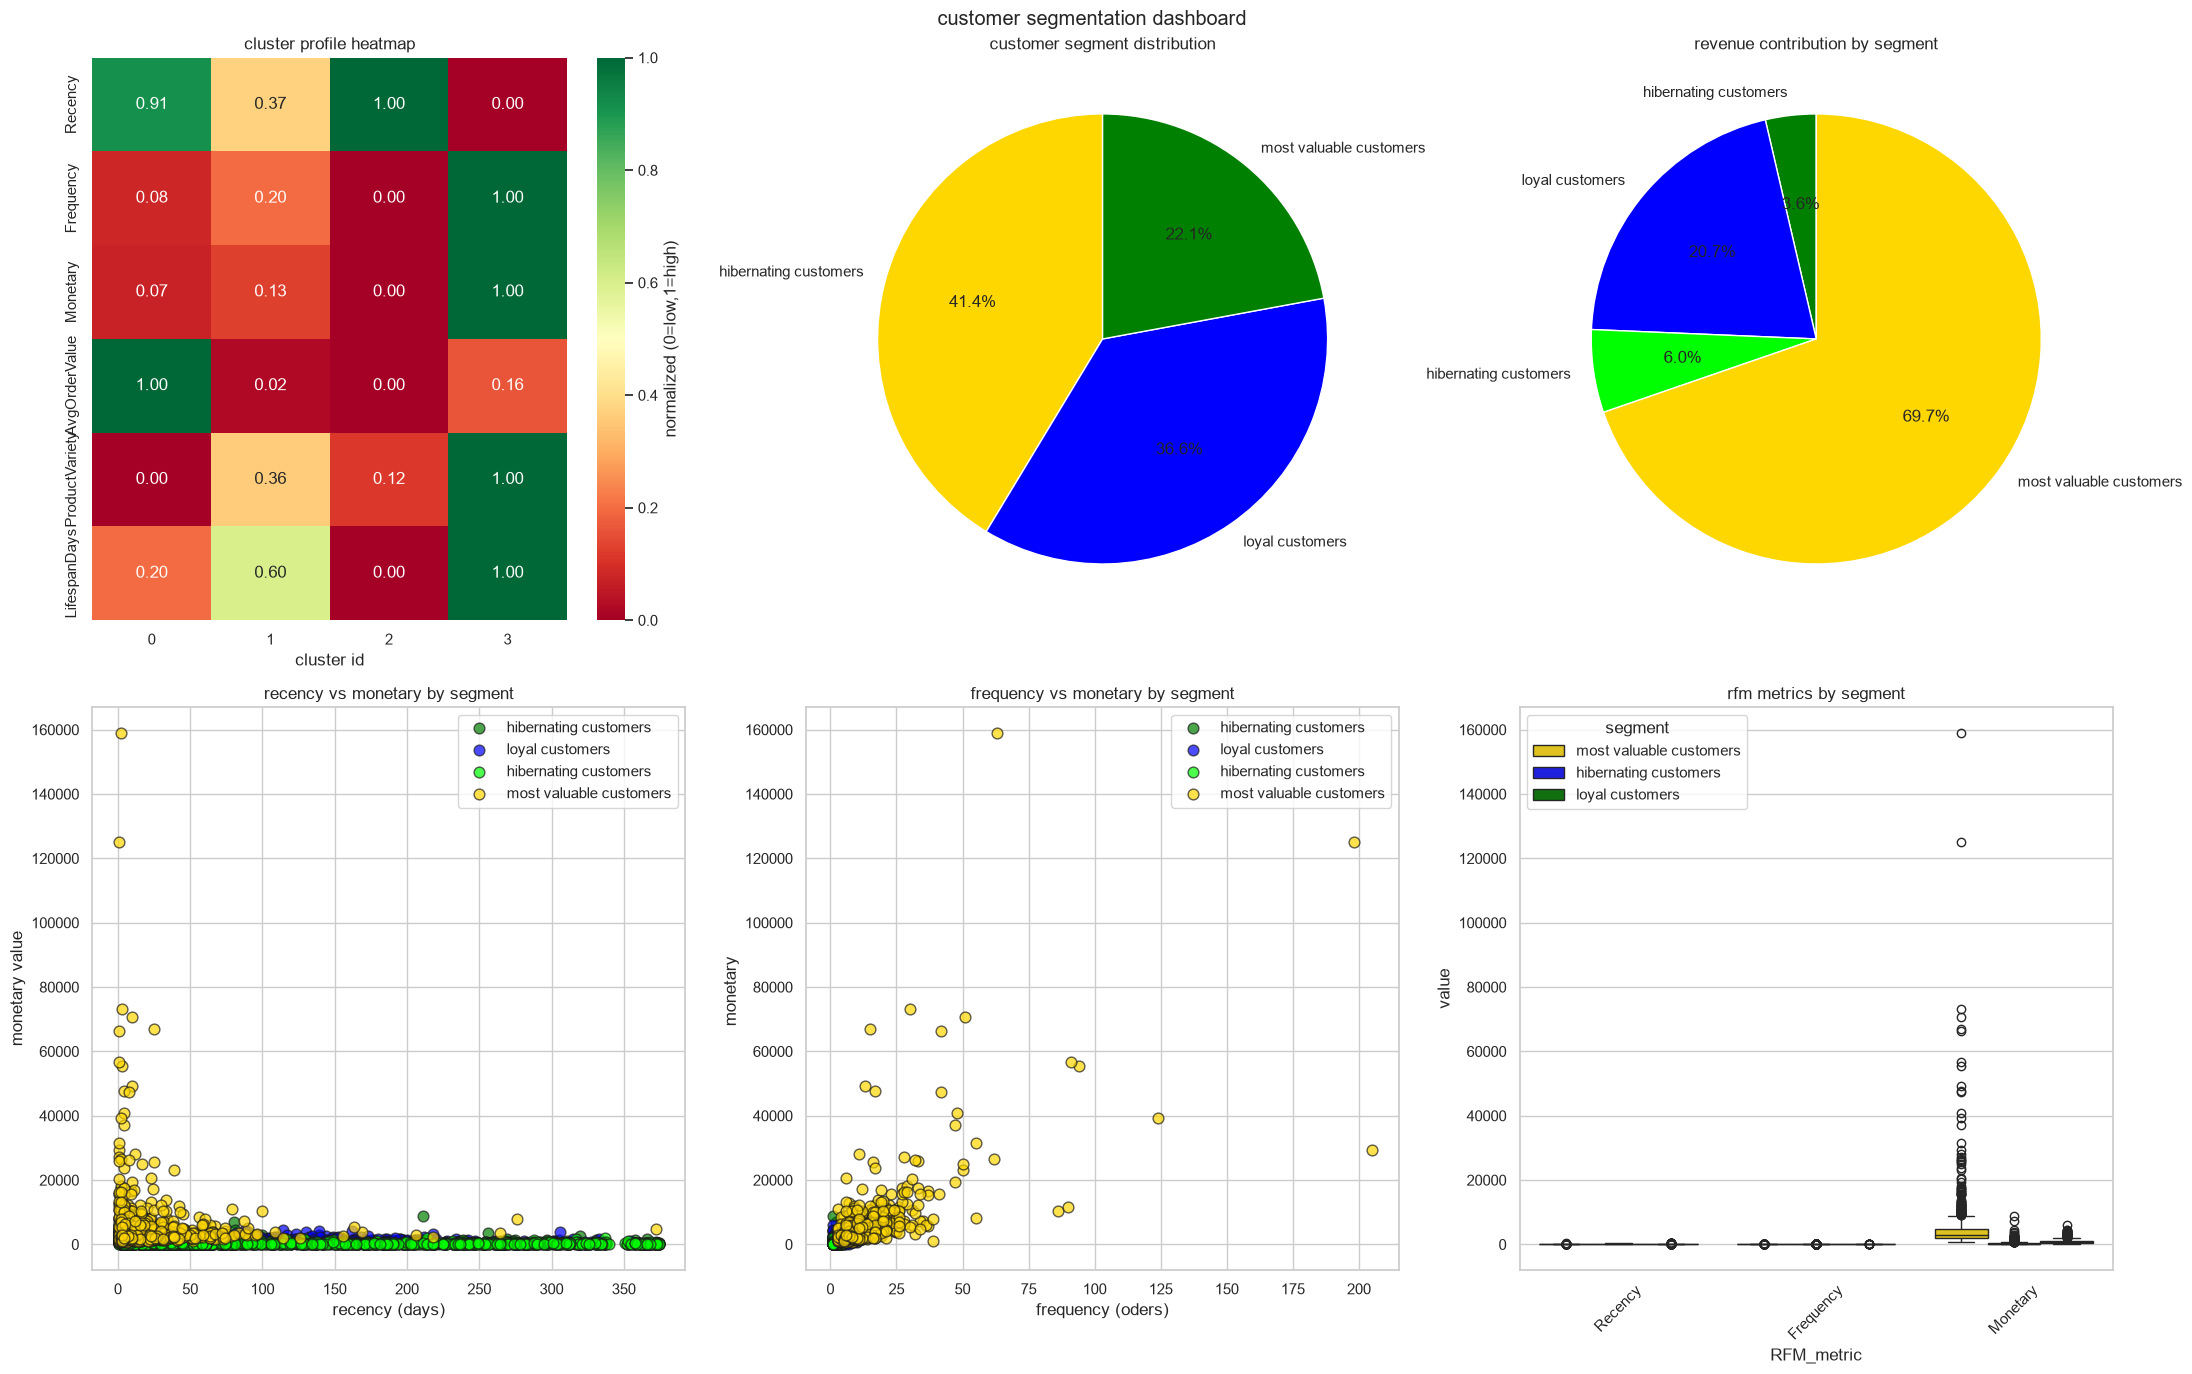

In [21]:
# dashboard visualization
fig,axes=plt.subplots(2,3,figsize=(22,14))
profile_norm=(cluster_profile-cluster_profile.min())/(cluster_profile.max()-cluster_profile.min())
sns.heatmap(profile_norm.T,annot=True,fmt='.2f',cmap='RdYlGn',ax=axes[0,0],cbar_kws={'label':'normalized (0=low,1=high)'})
axes[0,0].set_title('cluster profile heatmap')
axes[0,0].set_xlabel('cluster id')

segment_counts=rfm['segment'].value_counts()
axes[0,1].pie(segment_counts,labels=segment_counts.index,autopct='%1.1f%%',colors=[color_seg[c] for c in cluster_order],startangle=90)
axes[0,1].set_title('customer segment distribution')

revenue_by_cluster=rfm.groupby('cluster')['Monetary'].sum()
axes[0,2].pie(revenue_by_cluster,labels=[segment_names[c] for c in revenue_by_cluster.index],autopct='%1.1f%%',colors=[color_seg[c] for c in revenue_by_cluster.index],startangle=90)
axes[0,2].set_title('revenue contribution by segment')

for cid in sorted(rfm['cluster'].unique()):
    cluster_data=rfm[rfm['cluster']==cid]
    axes[1,0].scatter(cluster_data['Recency'],cluster_data['Monetary'],c=color_seg[cid],label=segment_names[cid],alpha=0.7,edgecolors='k',s=60)
axes[1,0].set_xlabel('recency (days)')
axes[1,0].set_ylabel('monetary value')
axes[1,0].set_title('recency vs monetary by segment')
axes[1,0].legend()


for cid in sorted(rfm['cluster'].unique()):
    cluster_data=rfm[rfm['cluster']==cid]
    axes[1,1].scatter(cluster_data['Frequency'],cluster_data['Monetary'],c=color_seg[cid],label=segment_names[cid],alpha=0.7,edgecolors='k',s=60)
    
axes[1,1].set_xlabel('frequency (oders)')
axes[1,1].set_ylabel('monetary ')
axes[1,1].set_title('frequency vs monetary by segment')
axes[1,1].legend()

rfm_melted=rfm.melt(id_vars=['segment'],value_vars=['Recency','Frequency','Monetary'],var_name='RFM_metric',value_name='value')
sns.boxplot(data=rfm_melted,x='RFM_metric',y='value',hue='segment',ax=axes[1,2],palette=[color_seg[c] for c in cluster_order])
axes[1,2].set_title('rfm metrics by segment')
axes[1,2].tick_params(axis='x',rotation=45)

plt.suptitle('customer segmentation dashboard')
plt.tight_layout()
plt.show()

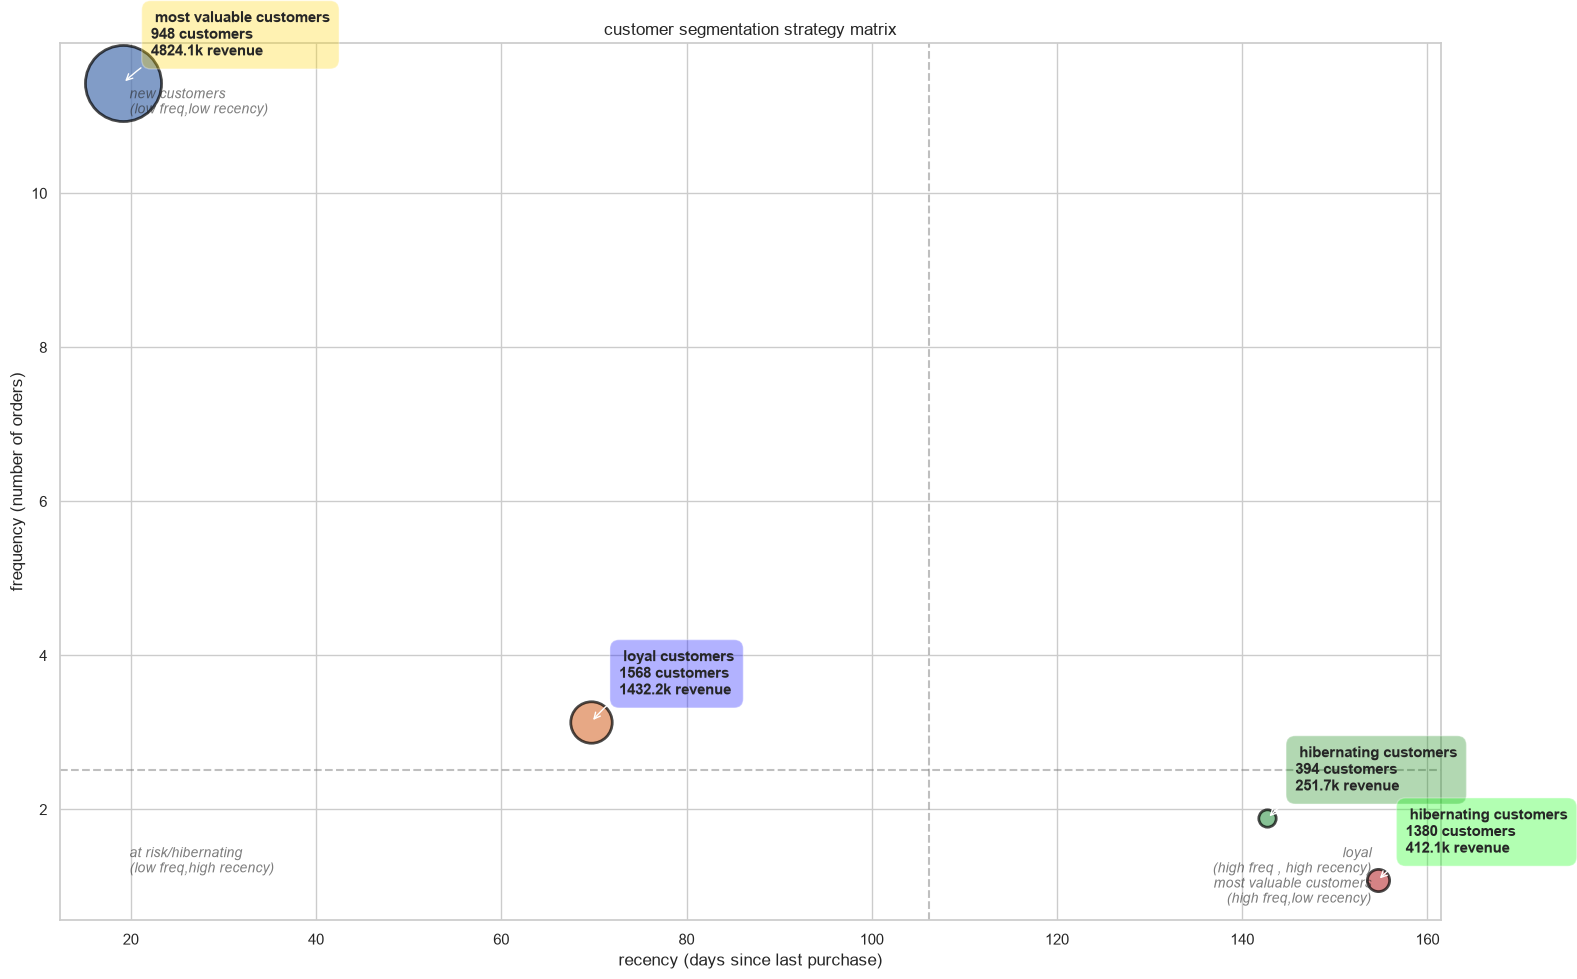

In [22]:
#strategy matrix
fig,ax=plt.subplots(figsize=(16,10))

segments_ordered=[segment_names[c] for c in cluster_order]
size=[len(rfm[rfm['cluster']==c]) for c in cluster_order]
revenue=[rfm[rfm['cluster']==c]['Monetary'].sum() for c in cluster_order]
recencies=[rfm[rfm['cluster']==c]['Recency'].mean() for c in cluster_order]
frequencies=[rfm[rfm['cluster']==c]['Frequency'].mean() for c in cluster_order]

bubble_size=np.array(revenue)/max(revenue)*3000

for i,(seg,rec,freq,rev,size) in enumerate(zip(segments_ordered,recencies,frequencies,revenue,size)):
    ax.scatter(rec,freq,s=bubble_size[i],alpha=0.7,edgecolors='black',linewidth=2,label=seg)
    ax.annotate(f' {seg}\n{size} customers\n{rev/1000:.1f}k revenue',
                (rec,freq),xytext=(20,20),textcoords='offset points',fontsize=11,fontweight='bold',bbox=dict(boxstyle='round,pad=0.6',facecolor=color_seg[cluster_order[i]],alpha=0.3),arrowprops=dict(arrowstyle='->',connectionstyle='arc3,rad=0.2'))
    
ax.set_xlabel('recency (days since last purchase)')
ax.set_ylabel('frequency (number of orders)')
ax.set_title('customer segmentation strategy matrix')
ax.axhline(y=np.median(frequencies),color='gray',linestyle='--',alpha=0.5)
ax.axvline(x=np.median(recencies),color='gray',linestyle='--',alpha=0.5)


ax.text(0.95,0.05,'most valuable customers\n(high freq,low recency)',transform=ax.transAxes,ha='right',va='top',fontsize=10,style='italic',alpha=0.6)
ax.text(0.05,0.95,'new customers\n(low freq,low recency)',transform=ax.transAxes,ha='left',va='top',fontsize=10,style='italic',alpha=0.6)
ax.text(0.95,0.05,'loyal\n(high freq , high recency)',transform=ax.transAxes,ha='right',va='bottom',fontsize=10,style='italic',alpha=0.6)
ax.text(0.05,0.05,'at risk/hibernating\n(low freq,high recency)',
        transform=ax.transAxes,ha='left',va='bottom',fontsize=10,style='italic',alpha=0.6)
plt.tight_layout()

plt.show()

In [23]:
# final summary
final_summary=[]
for cid in cluster_order:
    c_data=rfm[rfm['cluster']==cid]
    final_summary.append({
        'segment':segment_names[cid],
        'cluster_id':cid,
        'customers':len(c_data),
        'customer_pct': f"{len(c_data)/len(rfm)*100:.1f}%",
        'total_revenue':f"{c_data['Monetary'].sum():,.0f}",
        'revenue_pct':f"{c_data['Monetary'].sum()/rfm['Monetary'].sum()*100:.1f}%",
        'avg_recency':f"{c_data['Recency'].mean():.0f} days",
        'avg_Frequency':f"{c_data['Frequency'].mean():.1f}",
        'avg_monetary':f"{c_data['Monetary'].mean():.1f}",
        'strategy': strategies[cid]
    })

summary_df=pd.DataFrame(final_summary)

print('\n' + summary_df.to_string(index=False))




                segment  cluster_id  customers customer_pct total_revenue revenue_pct avg_recency avg_Frequency avg_monetary              strategy
most valuable customers           3        948        22.1%     4,824,149       69.7%     19 days          11.4       5088.8     reward and retain
        loyal customers           1       1568        36.6%     1,432,184       20.7%     70 days           3.1        913.4     engage and upsell
  hibernating customers           0        394         9.2%       251,702        3.6%    143 days           1.9        638.8 re-engage with offers
  hibernating customers           2       1380        32.2%       412,094        6.0%    155 days           1.1        298.6 re-engage with offers


In [24]:
# Save final EDA customer segments dataset
output_csv_path = PROCESSED_DIR / 'customer_segments_eda.csv'
rfm_export = rfm[['CustomerID', 'cluster', 'Recency', 'Frequency', 'Monetary']].copy()
if 'segment' in rfm.columns:
    rfm_export['segment'] = rfm['segment']

rfm_export.to_csv(output_csv_path, index=False)
print(f"Successfully saved customer segments to: {output_csv_path} ({rfm_export.shape[0]:,} customers)")


Successfully saved customer segments to: C:\--------projects------\Customer_Segmentation--UCI-\data\processed\customer_segments_eda.csv (4,290 customers)
